<a href="https://colab.research.google.com/github/AIVIETNAM-AIO-HUYTRUONG/AIO/blob/aio/M4-Foundation-DL/Optimization/W1/Linear%20Regression/Linear_Regression_va_Cac_Bien_The_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -q \
    "https://raw.githubusercontent.com/AIVIETNAM-AIO-HUYTRUONG/AIO/refs/heads/aio/helpers/dataset_helper.py" \
    -O /content/helper.py

%run /content/helper.py

In [ ]:
# https://raw.githubusercontent.com/AIVIETNAM-AIO-HUYTRUONG/AIO/refs/heads/aio/M4-Foundation-DL/Optimization/Data/advertising.csv
CSV_URL = input("Paste CSV URL: ").strip()

data = load_csv_with_numpy(
    url=CSV_URL,
    data_dir="/content/data",
    filename="advertising.csv"
)

data

Paste CSV URL: https://raw.githubusercontent.com/AIVIETNAM-AIO-HUYTRUONG/AIO/refs/heads/aio/M4-Foundation-DL/Optimization/Data/advertising.csv
Using existing dataset:
/content/data/advertising.csv
Dataset loaded successfully:
- Path: /content/data/advertising.csv
- Rows: 201
- Columns: 4


array([[  nan,   nan,   nan,   nan],
       [230.1,  37.8,  69.2,  22.1],
       [ 44.5,  39.3,  45.1,  10.4],
       [ 17.2,  45.9,  69.3,  12. ],
       [151.5,  41.3,  58.5,  16.5],
       [180.8,  10.8,  58.4,  17.9],
       [  8.7,  48.9,  75. ,   7.2],
       [ 57.5,  32.8,  23.5,  11.8],
       [120.2,  19.6,  11.6,  13.2],
       [  8.6,   2.1,   1. ,   4.8],
       [199.8,   2.6,  21.2,  15.6],
       [ 66.1,   5.8,  24.2,  12.6],
       [214.7,  24. ,   4. ,  17.4],
       [ 23.8,  35.1,  65.9,   9.2],
       [ 97.5,   7.6,   7.2,  13.7],
       [204.1,  32.9,  46. ,  19. ],
       [195.4,  47.7,  52.9,  22.4],
       [ 67.8,  36.6, 114. ,  12.5],
       [281.4,  39.6,  55.8,  24.4],
       [ 69.2,  20.5,  18.3,  11.3],
       [147.3,  23.9,  19.1,  14.6],
       [218.4,  27.7,  53.4,  18. ],
       [237.4,   5.1,  23.5,  17.5],
       [ 13.2,  15.9,  49.6,   5.6],
       [228.3,  16.9,  26.2,  20.5],
       [ 62.3,  12.6,  18.3,   9.7],
       [262.9,   3.5,  19.5,  17. ],
 

In [ ]:
import numpy as np
from numpy import genfromtxt
import matplotlib.pyplot as plt

# dataset
data = genfromtxt('/content/data/advertising.csv', delimiter=',', skip_header = 1)
N = data.shape[0]
X = data[:,:3]
y = data[:,3:]

### **Mean normalization**

- **Mean normalization (Chuẩn hóa giá trị trung bình)** là kỹ thuật tiền xử lý dữ liệu trong Machine Learning giúp điều chỉnh dữ liệu sao cho giá trị trung bình (mean) của đặc trưng trở thành 0, đồng thời giữ giá trị nằm trong một khoảng nhất định (thường đối xứng quanh 0 hoặc từ -1 đến 1)

- Công thức: $$\mathbf{x}^{\prime }=\frac{\mathbf{x}-\text{mean}(\mathbf{x})}{\max (\mathbf{x})-\min (\mathbf{x})}$$

- Mục đích và lợi ích:

  - Căn giữa dữ liệu (Center around zero): Giúp giá trị trung bình mới của đặc trưng bằng 0, loại bỏ hiện tượng lệch (bias) về độ lớn.

  - Đưa về cùng thang đo: Giúp các thuật toán dựa trên độ lớn hoặc tối ưu hóa bằng gradient (như Gradient Descent) hội tụ nhanh hơn, tránh việc một feature có giá trị số quá lớn làm lấn át các feature khác.
  
  - Lai giữa Min-Max và Z-score: Vừa giữ được hình dạng phân phối tương tự Min-Max Scaling vừa dịch chuyển tâm dữ liệu về số 0

In [ ]:
# Normalize input data by using mean normalization
def mean_normalization(X):
  i_max = np.max(X)
  i_min = np.min(X)
  avg = np.mean(X)

  X_norm = (X - avg) / (i_max - i_min)

  N = len(X)
  X_b = np.c_[np.ones((N, 1)), X_norm]
  return X_b, X_norm, i_max, i_min, avg

X_b, X_norm, i_max, i_min, avg = mean_normalization(X)

### **Stochastic Gradient Descent**

- **Ý tưởng cốt lõi**:
  - **Gradient Descent (GD) truyền thống**: Tính gradient trên **toàn bộ** tập dữ liệu huyến luyện mới cập nhật trọng số $w$ một lần. Cách này tốn nhiều thời gian và bộ nhớ khi dữ liệu lớn.
  - **Stochastic Gradient Descent (SGD)**: Thay vì dùng toàn bộ dữ liệu, **SGD** chỉ chọn ngẫu nhiên một mẫu dữ liệu duy nhất để tính gradient và cập nhật trọng số ngay lặp tức

  - Ưu điểm:
    - Tốc độ nhanh hơn: Cập nhật liên tục trên từng mẫu giúp quá trình học diễn ra nhanh qua mỗi vòng lặp.

    - Nhược điểm:
      - Đường đi zíc zắc: Do mỗi mẫu dữ liệu không đại diện hoàn hảo cho toàn bộ tập dữ liệu, hàm mất mát không giảm theo một đường thẳng mượt mà mà dao động mạnh.
      -  Cần điều chỉnh tốc độ học (learning rate) cẩn thận để thuật toán có thể hội tụ thay vì dao động quanh điểm cực tiểu.

In [ ]:
def initialize_params():
   return np.asanyarray([
      [1.16270837],
      [-0.81960489],
      [1.39501033],
      [0.29763545]
  ])

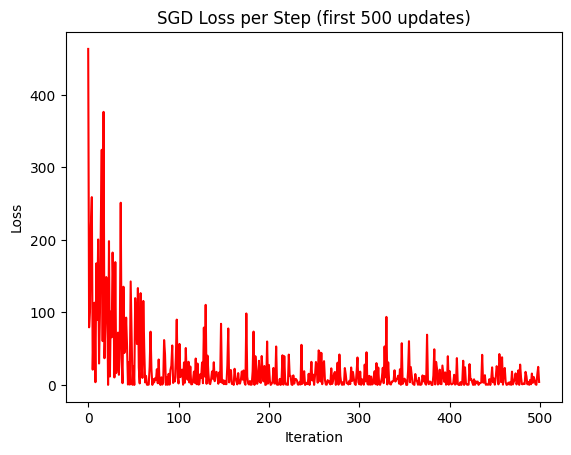

In [ ]:
def stochastic_gradient_descent(X_b, y, n_epochs=50, learning_rate=0.01):
  N, d_plus1 = X_b.shape
  # Step 1: Init parameters
  thetas = initialize_params()

  thetas_path = [thetas.copy()]
  losses = []

  # Step 2: SGD loop
  for epoch in range(n_epochs):
    for i in range(N):
      random_index = i
      xi = X_b[random_index:random_index+1]
      yi = y[random_index:random_index+1]

      # Step 3: prediction using current theta
      yi_hat = xi.dot(thetas)

      # Step 4: MSE loss for 1 sample
      loss =  (yi_hat - yi) ** 2

      # Step 5: gradient for 1 sample
      gradients = 2 * xi.T.dot(yi_hat - yi)

      # Step 6: update current theta
      thetas = thetas - learning_rate * gradients

      # Log
      thetas_path.append(thetas.copy())
      losses.append(loss[0][0])

  return thetas_path, losses

thetas_path, losses = stochastic_gradient_descent(X_b, y, n_epochs=50, learning_rate=0.01)

x_axis = list(range(500))
plt.plot(x_axis, losses[:500], color="r")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("SGD Loss per Step (first 500 updates)")
plt.show()

### **Mini-batch Gradient Descent**

- Mini-batch Gradient Descent là một biến thể của thuật toán tối ưu hóa Gradient Descent trong Học máy (Machine Learning) và Học sâu (Deep Learning). Nó chia toàn bộ tập dữ liệu huấn luyện thành nhiều tập con nhỏ hơn gọi là mini-batch (thường có kích thước từ 50 đến 100 mẫu) để tính toán độ dốc và cập nhật trọng số của mô hìn

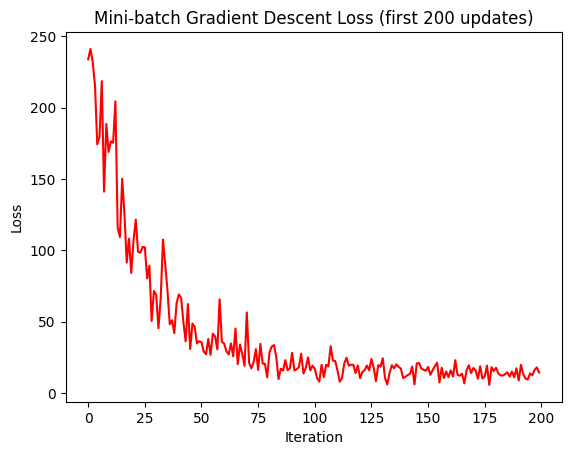

In [ ]:
def mini_batch_gradient_descent(X_b, y, n_epochs=50, minibatch_size=20, learning_rate=0.01):
  N, d_plus1 = X_b.shape

  # Step 1: Init parameters
  thetas = initialize_params()

  thetas_path = [thetas.copy()]
  losses = []

  for epoch in range(n_epochs):

    # shuffle data
    shuffled_indices = np.random.permutation(N)
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]

    for i in range(0, N, minibatch_size):
      xi = X_b_shuffled[i:i+minibatch_size] # (m, d+1)
      yi = y_shuffled[i:i+minibatch_size]   # (m, 1)

      # Step 3: prediction
      yi_hat = xi.dot(thetas)

      # Step 4: MSE loss for minibatch
      loss = np.mean((yi_hat - yi) ** 2)

      # Step 5: gradient for minibatch
      m = xi.shape[0]
      gradients = 2/m * xi.T.dot(yi_hat - yi)

      # Step 6: update current theta
      thetas = thetas - learning_rate * gradients

      # Log
      thetas_path.append(thetas.copy())
      losses.append(loss)
  return thetas_path, losses

mbgd_thetas, losses = mini_batch_gradient_descent(X_b, y, n_epochs=50, minibatch_size=20, learning_rate=0.01)

x_axis = list(range(200))
plt.plot(x_axis, losses[:200], color="r")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Mini-batch Gradient Descent Loss (first 200 updates)")
plt.show()

### **Batch Gradient Descent**

- Batch Gradient Descent (giảm độ dốc theo lô) là một thuật toán tối ưu hóa trong học máy (Machine Learning) dùng để giảm thiểu hàm mất mát (loss function) bằng cách sử dụng toàn bộ tập dữ liệu huấn luyện trong mỗi lần cập nhật trọng số

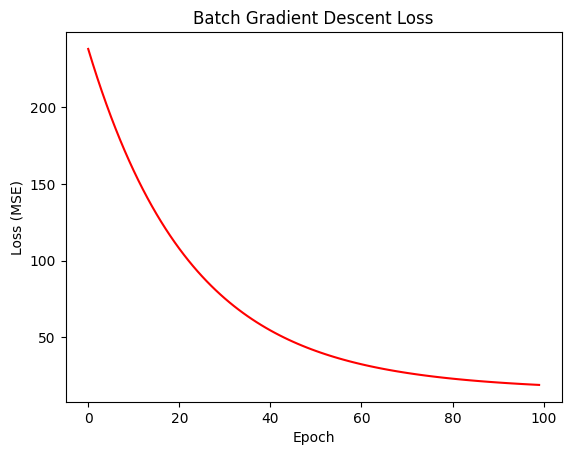

In [ ]:
def batch_gradient_descent(X_b, y, n_epochs=100, learning_rate=0.01):
  N, d_plus1 = X_b.shape

  # Step 1: Init parameters
  thetas = initialize_params()
  thetas_path = [thetas.copy()]
  losses = []

  for epoch in range(n_epochs):
    # Step 3: prediction
    y_hat = X_b.dot(thetas)

    # Step 4: MSE loss
    loss = np.mean((y_hat - y) ** 2)

    # Step 5: gradient
    gradients = (2 / N) * X_b.T.dot(y_hat - y)

    # Step 6: update parameters
    thetas = thetas - learning_rate * gradients

    #log
    thetas_path.append(thetas.copy())
    losses.append(loss)
  return thetas_path, losses

bgd_thetas, losses = batch_gradient_descent(X_b, y, n_epochs=100, learning_rate=0.01)

# visualize
x_axis = list(range(100))
plt.plot(x_axis, losses[:100], color="r")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Batch Gradient Descent Loss")
plt.show()